# 🚀 Day 15 Challenge: Startup in a Box

> *"Every great company started as a crazy idea on a napkin. Your job: build the machine that turns napkins into Demo Day pitches."*

## 📖 The Story

**Moonshot Ventures**, a (fictional) venture studio, receives hundreds of wild product ideas every week. Their analysts can't keep up, so they've hired **you** as their founding AI engineer.

Your mission is to build an **AI venture studio**: a multi-agent system that takes **one wild idea** and turns it into a complete **🚀 Launch Kit**. The kit covers brand, market research, product plan, unit economics, a marketing campaign and an investor pitch, and it has to survive a tough **investor panel** at Demo Day.

You choose the framework. You design the team. You decide how the agents work together. 🧠

## 🎯 Rules of the Game

### ✅ Your system must…
1. **Use one agent framework** from Days 14–15 as its backbone: `smolagents`, `LangGraph`, `LlamaIndex`, `Google ADK` or `CrewAI`.
2. **Have at least 3 agents** with clearly different roles.
3. **Combine at least 2 agentic patterns** of your choice, and explain why in your design doc.
4. **Let agents call at least 2 tools**, from the Startup Toolkit or your own. The LLM should decide when to call them; don't call them yourself.
5. **Produce a `launch_kit` dictionary** that passes the Mission Check (section 7).
6. **Run top to bottom** after *Restart Kernel → Run All*.

### 🎨 You are free to…
- pick an idea from the deck **or invent your own**,
- design any architecture: a pipeline, a graph, a hierarchy, a debate, a swarm…,
- choose the agents, roles, prompts, tools and patterns, and how many iterations they get,
- add extra sections to the launch kit (logo prompt, landing page, customer interviews, risk register…).

### 🤝 Fair play
- The agents must generate the content. No hard-coding the answers!
- Keep a full run under **~50 LLM calls**, because we all share one Azure OpenAI quota.
- Never print, hard-code or commit API keys.

## 📦 The Launch Kit (your deliverable)

Your system must produce a Python `dict` called **`launch_kit`** with the keys below. Values can be strings, lists, dicts or Pydantic models; the format inside each section is up to you.

| Key | What it should contain |
|---|---|
| `startup_name` | A catchy name you've checked is available |
| `one_liner` | A one-sentence elevator pitch |
| `target_customers` | Who exactly it's for (personas/segments) |
| `market_insights` | Market size, growth, trends and risks |
| `competitors` | Main competitors and how you'll beat them |
| `mvp_features` | A prioritised list of MVP features |
| `pricing` | Pricing model and price points |
| `unit_economics` | LTV, CAC, LTV/CAC and payback, calculated with the tool |
| `marketing_campaign` | Slogan, launch channels and a few social posts |
| `investor_pitch` | Your Demo Day pitch (e.g. a 6-slide outline or a 200-word script) |
| `investor_feedback` | What the investor panel said (scores, verdicts, what changed) |

Extra keys are welcome. `show_launch_kit()` renders them too, and it will even display a `landing_page_html` section as a web page. 🌐

## ⏱️ Suggested Time Plan (2–3 hours)

| Phase | Suggested time |
|---|---|
| 📖 Read the brief, explore the toolkit, pick an idea | 15 min |
| 📝 Design your system (section 4) | 20 min |
| 🛠️ Set up your framework, model and tools | 20 min |
| 🤖 Build your agents and workflow | 60–75 min |
| 🚀 Launch, run the Mission Check, iterate | 20 min |
| 🪞 Reflection | 10 min |
| 🌟 Bonus missions | Any time left |

## 🏆 How You'll Be Evaluated (100 points + bonus)

| Criterion | Points | What we look for |
|---|---|---|
| 🛠️ It works | 10 | Runs top to bottom, and the Mission Check passes 11/11 |
| 🧠 Architecture & patterns | 20 | At least 3 agents with clear roles, at least 2 patterns that genuinely fit the problem, and sensible stop conditions |
| 🔧 Tool use | 10 | Agents call tools on their own, and the tool results visibly shape the output (e.g. real numbers in the unit economics) |
| 🎨 Creativity & quality | 10 | A coherent, convincing and fun launch kit, plus original agent roles or workflow ideas |
| 📝 Design & reflection | 50 | A clear design doc and an honest, insightful reflection |

## 🌟 Bonus Missions (up to +20)
1. 🦈 **Shark Tank loop:** make each investor from `get_investor_panel()` its own agent, and revise the pitch until the average score is ≥ 8 (max 3 rounds).
2. 🧑‍💼 **Human-in-the-loop:** you, the founder, approve or veto the name or the pitch with `input()` during the run.
3. 📐 **Structured outputs:** agents return Pydantic models that slot straight into the launch kit.
4. 🌐 **Landing page:** an agent writes `launch_kit["landing_page_html"]`, and `show_launch_kit()` renders it.
5. 📊 **Observability:** count LLM calls, tokens and time per stage (or trace the run with LangSmith).
6. 🥊 **Pitch battle:** run two ideas through your studio and let the investor panel pick the winner.
7. 🔁 **Framework remix:** rebuild one part of your system in a second framework and compare the two.

## 0. 🧩 Choose Your Framework

Pick **one** framework as the backbone of your venture studio. Each card shows how to connect it to Azure OpenAI and wrap a toolkit function as a tool (the toolkit is loaded in section 2). **How you design the system is up to you.**

> 📦 **No manual installs needed:** set `FRAMEWORK` in the install cell of section 1, and it installs the right packages for you.
>
> 🐍 **Python versions:** Google ADK needs Python ≥ 3.11, and CrewAI supports Python 3.10–3.13. Google Colab works for all five frameworks.
>
> ⚠️ **CrewAI** pins many of its own dependency versions. Run it in a fresh environment (a new Colab runtime or a dedicated virtual environment), and don't install other frameworks into the same one.

<details>
<summary><b>🤗 smolagents</b></summary>

```python
from smolagents import CodeAgent, OpenAIModel, ToolCallingAgent, tool

model = OpenAIModel(model_id=AZURE_OPENAI_DEPLOYMENT, api_base=AZURE_OPENAI_ENDPOINT,
                    api_key=os.environ["AZURE_OPENAI_API_KEY"])
market_tool = tool(get_market_data)  # wrap any toolkit function

analyst = ToolCallingAgent(tools=[market_tool], model=model, max_steps=5,
                           name="market_analyst", description="Researches markets")
print(analyst.run("Summarise the pets market."))
```

**Useful:** `managed_agents=[...]` builds manager → worker hierarchies. Use `ToolCallingAgent` for writing tasks and `CodeAgent` when the agent should compute.
</details>

<details>
<summary><b>🕸️ LangGraph</b></summary>

```python
from langchain.agents import create_agent
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph

llm = ChatOpenAI(model=AZURE_OPENAI_DEPLOYMENT, base_url=AZURE_OPENAI_ENDPOINT,
                 api_key=os.environ["AZURE_OPENAI_API_KEY"])
analyst = create_agent(llm, tools=[tool(get_market_data)], system_prompt="You are a market analyst.")
result = analyst.invoke({"messages": [{"role": "user", "content": "Summarise the pets market."}]})
print(result["messages"][-1].content)
```

**Useful:** `StateGraph` nodes and edges, `add_conditional_edges` for routing and loops, fan-out edges for parallelism, `llm.with_structured_output(MyPydanticModel)`, and `create_agent(..., response_format=MyPydanticModel)`.
</details>

<details>
<summary><b>🦙 LlamaIndex</b></summary>

```python
from llama_index.core.agent.workflow import AgentWorkflow, FunctionAgent
from llama_index.llms.openai import OpenAI

llm = OpenAI(model=AZURE_OPENAI_DEPLOYMENT, api_base=AZURE_OPENAI_ENDPOINT,
             api_key=os.environ["AZURE_OPENAI_API_KEY"])
analyst = FunctionAgent(name="market_analyst", description="Researches markets",
                        tools=[get_market_data, search_competitors], llm=llm,
                        system_prompt="You are a market analyst.")
response = await analyst.run(user_msg="Summarise the pets market.")
print(response)
```

**Useful:** `AgentWorkflow(agents=[...], root_agent=...)` for hand-offs between agents, custom `Workflow` classes with `@step` for full control, and `llm.as_structured_llm(MyPydanticModel)`.
</details>

<details>
<summary><b>🧪 Google ADK</b></summary>

```python
import litellm
from google.adk.agents import LlmAgent, LoopAgent, ParallelAgent, SequentialAgent
from google.adk.models.lite_llm import LiteLlm
from google.adk.runners import InMemoryRunner

litellm.suppress_debug_info = True
model = LiteLlm(model=f"openai/{AZURE_OPENAI_DEPLOYMENT}", api_base=AZURE_OPENAI_ENDPOINT,
                api_key=os.environ["AZURE_OPENAI_API_KEY"])
analyst = LlmAgent(name="market_analyst", model=model, instruction="You are a market analyst.",
                   tools=[get_market_data], output_key="market_report")
runner = InMemoryRunner(agent=analyst, app_name="startup_studio")
events = await runner.run_debug("Summarise the pets market.")
```

**Useful:** the workflow agents `SequentialAgent`, `ParallelAgent` and `LoopAgent`. `output_key` saves an agent's answer in session state, and `{market_report}` in another agent's instruction reads it back. `sub_agents=[...]` lets the LLM delegate.
</details>

<details>
<summary><b>👥 CrewAI</b> (use a fresh environment)</summary>

```python
from crewai import LLM, Agent, Crew, Process, Task
from crewai.tools import tool

llm = LLM(model=f"openai/{AZURE_OPENAI_DEPLOYMENT}", base_url=AZURE_OPENAI_ENDPOINT,
          api_key=os.environ["AZURE_OPENAI_API_KEY"])
market_tool = tool("Market Data")(get_market_data)

analyst = Agent(role="Market Analyst", goal="Size up startup markets", backstory="You love data.",
                tools=[market_tool], llm=llm)
task = Task(description="Summarise the {sector} market.", expected_output="3 bullet points", agent=analyst)
crew = Crew(agents=[analyst], tasks=[task], process=Process.sequential)
result = await crew.kickoff_async(inputs={"sector": "pets"})  # in notebooks, always use kickoff_async
print(result)
```

**Useful:** `context=[...]` chains tasks, `async_execution=True` runs tasks in parallel, `Process.hierarchical` with `manager_llm=llm` adds a manager agent, and `output_pydantic=MyPydanticModel` gives structured outputs.
</details>

## 1. ⚙️ Setup

### 📦 Install packages

Set `FRAMEWORK` to the framework you picked in section 0 and run the cell. It installs the base packages (`python-dotenv`, `openai`) plus everything your framework needs. If you change your mind later, update `FRAMEWORK` and run it again.

> 💡 On **Google Colab**, if you're asked to restart the session after installing, restart it and continue with the next cell.

In [6]:
FRAMEWORK = "langgraph"  # <- choose one: "smolagents", "langgraph", "llamaindex", "google_adk", "crewai"

BASE_PACKAGES = ["python-dotenv", "openai"]
FRAMEWORK_PACKAGES = {
    "smolagents": ["smolagents[openai]>=1.26"],
    "langgraph": ["langgraph", "langchain", "langchain-openai"],
    "llamaindex": ["llama-index-core", "llama-index-llms-openai"],
    "google_adk": ["google-adk[mcp]>=2.12", "litellm>=1.84", "mcp>=2.2"],  # LiteLLM needs the MCP SDK for tool calls
    "crewai": ["crewai>=1.15"],
}

# Need extra packages for your own tools? Add them to BASE_PACKAGES.
install_args = " ".join(f'"{p}"' for p in BASE_PACKAGES + FRAMEWORK_PACKAGES.get(FRAMEWORK, []))
%pip install -q {install_args}

# Windows only: pywin32 (used by the MCP SDK in ADK and CrewAI) normally needs a kernel restart after
# installation. Re-reading the site-packages .pth files makes it importable right away.
import site, sys, sysconfig
if sys.platform == "win32":
    for _site_dir in (sysconfig.get_paths()["purelib"], site.getusersitepackages()):
        site.addsitedir(_site_dir)

if FRAMEWORK in FRAMEWORK_PACKAGES:
    print(f"✅ Installed the base packages + {FRAMEWORK}. Happy building!")
else:
    print(f"⚠️ Only the base packages were installed. Set FRAMEWORK to one of: {', '.join(FRAMEWORK_PACKAGES)} and run this cell again.")

Note: you may need to restart the kernel to use updated packages.
✅ Installed the base packages + langgraph. Happy building!



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### 🔐 Azure OpenAI credentials

All agents run on an **Azure OpenAI** deployment through its OpenAI-compatible **v1 endpoint**.
Credentials are read from a `.env` file in this notebook's folder (or any parent folder). Copy `example.env` to `.env` and fill it in. On **Google Colab**, upload `.env` with the 📁 *Files* panel, or just enter the values when prompted:

| Variable | Description |
|----------|-------------|
| `AZURE_OPENAI_API_KEY` | Your Azure OpenAI API key |
| `AZURE_OPENAI_ENDPOINT` | Base URL, e.g. `https://<resource>.openai.azure.com/` (the full `.../openai/v1/` URL also works) |
| `AZURE_OPENAI_DEPLOYMENT` | Deployment (model) name: `gpt-5.4-mini` or `gpt-5.6-luna` |

If a value is missing, you'll be prompted for it. **Never hardcode API keys.**

In [7]:
import getpass
import os

from dotenv import find_dotenv, load_dotenv

load_dotenv(find_dotenv(usecwd=True))

if not os.environ.get("AZURE_OPENAI_API_KEY"):
    os.environ["AZURE_OPENAI_API_KEY"] = getpass.getpass("Enter your Azure OpenAI API key: ")
if not os.environ.get("AZURE_OPENAI_ENDPOINT"):
    os.environ["AZURE_OPENAI_ENDPOINT"] = input("Enter your Azure OpenAI endpoint (https://<resource>.openai.azure.com/): ")

# Accept either the resource URL or the full v1 base URL
AZURE_OPENAI_ENDPOINT = os.environ["AZURE_OPENAI_ENDPOINT"].rstrip("/").removesuffix("/openai/v1") + "/openai/v1/"
AZURE_OPENAI_DEPLOYMENT = os.environ.get("AZURE_OPENAI_DEPLOYMENT", "gpt-5.4-mini")
print(f"Using Azure OpenAI deployment: {AZURE_OPENAI_DEPLOYMENT}")

Using Azure OpenAI deployment: gpt-5.4-mini


### 📡 Connection test

This framework-independent check calls your deployment once with the plain `openai` SDK. If it prints a reply, you're ready for launch.

In [8]:
from openai import OpenAI

client = OpenAI(base_url=AZURE_OPENAI_ENDPOINT, api_key=os.environ["AZURE_OPENAI_API_KEY"])
reply = client.chat.completions.create(
    model=AZURE_OPENAI_DEPLOYMENT,
    messages=[{"role": "user", "content": "You are mission control. Confirm we are ready for launch in one short, upbeat sentence."}],
)
print(reply.choices[0].message.content)

All systems are green—ready for launch!


## 2. 🧰 The Startup Toolkit

Run the cell below to load the **Startup Toolkit**: fictional market data, a competitor database, an investor panel and a set of ready-made **tools** for your agents.

| Tool | What it does |
|---|---|
| `get_market_data(sector)` | Market size, growth, trends, risks and benchmark CAC & churn for a sector |
| `search_competitors(keyword)` | Up to 5 competitors matching a keyword, with pricing and their main weakness |
| `check_name_availability(name)` | Checks `.com`/`.ai` domains and trademark risk for a startup name |
| `estimate_unit_economics(price, cost, cac, churn)` | Calculates LTV, LTV/CAC and payback period, with a verdict |
| `get_investor_panel()` | Profiles of the Demo Day investors: what they love, hate and ask about |

**Helpers (not tools):** `draw_wild_idea()`, `check_launch_kit()`, `show_launch_kit()`. **Raw data:** `WILD_IDEA_DECK`, `MARKET_DATA`, `COMPETITORS`, `INVESTOR_PANEL`.

> 💡 Every tool is a plain Python function with type hints and a docstring, so **any framework** can turn it into a tool (see the cheat sheet in section 0). You can also write your own tools! All data is fictional.

In [2]:
# 🧰 The Startup Toolkit: fictional mock data + framework-agnostic tools.
# Every tool is a plain Python function with type hints and a docstring,
# so you can wrap it with any framework's tool helper (see the cheat sheet).
import hashlib
import json
import random
import re

from IPython.display import HTML, Markdown, display

# ---------------------------------------------------------------------------
# 🃏 The Wild Idea Deck
# ---------------------------------------------------------------------------
WILD_IDEA_DECK = [
    {"id": 1, "sector": "home",
     "idea": "An on-demand app that matches travelling plant owners with vetted 'plant sitters' who water, talk to, and send selfies of your plants."},
    {"id": 2, "sector": "entertainment",
     "idea": "An AI dream journal that turns parents' dreams into personalised bedtime stories for their kids."},
    {"id": 3, "sector": "pets",
     "idea": "Noise-cancelling headphones for dogs that switch on automatically during fireworks and thunderstorms."},
    {"id": 4, "sector": "food",
     "idea": "A smart lunchbox and companion app that turns eating vegetables into a game for picky kids."},
    {"id": 5, "sector": "education",
     "idea": "A language-learning app where you practise by debating AI versions of historical figures."},
    {"id": 6, "sector": "social",
     "idea": "'Grandparents-as-a-Service': matching retirees with busy families for storytelling, homework help and cooking lessons."},
    {"id": 7, "sector": "fitness",
     "idea": "Gym equipment that turns your workout into electricity and credits it to your home energy bill."},
    {"id": 8, "sector": "sustainability",
     "idea": "Carbon-negative coffee pods grown from mushroom mycelium that you can plant in your garden after use."},
    {"id": 9, "sector": "mobility",
     "idea": "A marketplace where office buildings rent their empty parking spots to food trucks at lunchtime."},
    {"id": 10, "sector": "entertainment",
     "idea": "A dating app for board-game lovers where every first date is a cooperative game night."},
]

# ---------------------------------------------------------------------------
# 📊 Fictional market data (numbers are made up for this exercise!)
# ---------------------------------------------------------------------------
MARKET_DATA = {
    "home": {"market_size_usd_bn": 48, "annual_growth_pct": 7.5, "avg_spend_usd_per_month": 25,
             "trends": ["Urban apartment gardening boom", "Gig-economy home services", "Smart-home sensors"],
             "risks": ["Trust & safety for in-home visits", "Seasonal demand (holidays)", "Low willingness to pay"],
             "benchmarks": {"typical_cac_usd": 30, "typical_monthly_churn_pct": 8}},
    "entertainment": {"market_size_usd_bn": 210, "annual_growth_pct": 9.2, "avg_spend_usd_per_month": 12,
                      "trends": ["Generative-AI personalised content", "Niche communities over mass platforms", "Offline-first experiences"],
                      "risks": ["Content moderation", "Subscription fatigue", "Fast-moving copycats"],
                      "benchmarks": {"typical_cac_usd": 18, "typical_monthly_churn_pct": 9}},
    "pets": {"market_size_usd_bn": 320, "annual_growth_pct": 6.1, "avg_spend_usd_per_month": 120,
             "trends": ["Pet humanisation ('fur babies')", "Premium wellness & anxiety products", "Subscription boxes"],
             "risks": ["Animal-welfare and vet claims", "Hardware returns", "Seasonal spikes (fireworks season)"],
             "benchmarks": {"typical_cac_usd": 35, "typical_monthly_churn_pct": 6}},
    "food": {"market_size_usd_bn": 95, "annual_growth_pct": 5.4, "avg_spend_usd_per_month": 40,
             "trends": ["Healthy eating for kids", "Gamified nutrition", "Connected kitchen devices"],
             "risks": ["Food-safety regulations", "Parents' screen-time concerns", "Hardware margins"],
             "benchmarks": {"typical_cac_usd": 40, "typical_monthly_churn_pct": 7}},
    "education": {"market_size_usd_bn": 165, "annual_growth_pct": 12.8, "avg_spend_usd_per_month": 15,
                  "trends": ["AI tutors and conversation practice", "Gamification", "Micro-learning"],
                  "risks": ["Low completion rates", "Historical accuracy & bias", "Free alternatives"],
                  "benchmarks": {"typical_cac_usd": 22, "typical_monthly_churn_pct": 10}},
    "social": {"market_size_usd_bn": 60, "annual_growth_pct": 8.0, "avg_spend_usd_per_month": 80,
               "trends": ["Loneliness economy", "Intergenerational connection", "Care marketplaces"],
               "risks": ["Safeguarding & background checks", "Two-sided marketplace cold start", "Insurance"],
               "benchmarks": {"typical_cac_usd": 55, "typical_monthly_churn_pct": 5}},
    "fitness": {"market_size_usd_bn": 105, "annual_growth_pct": 6.9, "avg_spend_usd_per_month": 45,
                "trends": ["Gamified workouts", "Sustainability-minded consumers", "Connected equipment"],
                "risks": ["Expensive hardware", "Energy regulations", "Motivation drop-off after January"],
                "benchmarks": {"typical_cac_usd": 60, "typical_monthly_churn_pct": 6}},
    "sustainability": {"market_size_usd_bn": 140, "annual_growth_pct": 14.5, "avg_spend_usd_per_month": 30,
                       "trends": ["Carbon-negative products", "Bio-materials (mycelium, algae)", "Circular economy"],
                       "risks": ["Greenwashing accusations", "Manufacturing scale-up", "Premium pricing"],
                       "benchmarks": {"typical_cac_usd": 45, "typical_monthly_churn_pct": 4}},
    "mobility": {"market_size_usd_bn": 75, "annual_growth_pct": 10.3, "avg_spend_usd_per_month": 200,
                 "trends": ["Under-used urban space", "Food-truck culture", "B2B marketplaces"],
                 "risks": ["City permits & zoning", "Liability", "Chicken-and-egg marketplace dynamics"],
                 "benchmarks": {"typical_cac_usd": 150, "typical_monthly_churn_pct": 3}},
}

# ---------------------------------------------------------------------------
# 🏢 Fictional competitor database
# ---------------------------------------------------------------------------
COMPETITORS = [
    {"name": "Leafy Nanny", "sector": "home", "tagline": "Plant-care tips from a chatbot", "keywords": ["plants", "plant care", "gardening"], "pricing": "$4.99/month", "weakness": "No in-person service"},
    {"name": "GreenThumb Robotics", "sector": "home", "tagline": "Self-watering smart pots", "keywords": ["plants", "smart pot", "watering", "iot"], "pricing": "$89 one-time", "weakness": "Only works with their own pots"},
    {"name": "SnoozeStory", "sector": "entertainment", "tagline": "AI bedtime stories on demand", "keywords": ["bedtime", "stories", "kids", "ai", "parents"], "pricing": "$7.99/month", "weakness": "Generic stories, nothing from the family's own life"},
    {"name": "DreamLog", "sector": "entertainment", "tagline": "Track and analyse your dreams", "keywords": ["dream", "journal", "sleep"], "pricing": "Free / $3.99 pro", "weakness": "Analysis only, no creative output"},
    {"name": "Roll for Love", "sector": "entertainment", "tagline": "Dating for video gamers", "keywords": ["dating", "games", "gamers"], "pricing": "Freemium, $14.99/month", "weakness": "Video games only, no tabletop community"},
    {"name": "StormHug", "sector": "pets", "tagline": "Anxiety-calming vests for dogs", "keywords": ["dog", "anxiety", "fireworks", "thunder"], "pricing": "$45 one-time", "weakness": "Doesn't address noise itself"},
    {"name": "Barkly Box", "sector": "pets", "tagline": "Monthly toy & treat box for dogs", "keywords": ["dog", "subscription", "toys", "treats"], "pricing": "$29/month", "weakness": "Commodity product, high churn"},
    {"name": "VeggieQuest", "sector": "food", "tagline": "Nutrition game app for kids", "keywords": ["kids", "vegetables", "game", "nutrition"], "pricing": "$5.99/month", "weakness": "Parents worry about extra screen time"},
    {"name": "LunchBotics", "sector": "food", "tagline": "Temperature-controlled smart bento", "keywords": ["lunchbox", "smart", "kids", "bento"], "pricing": "$129 one-time", "weakness": "Expensive, no engagement features"},
    {"name": "Lingo Legends", "sector": "education", "tagline": "Learn languages through quests", "keywords": ["language", "learning", "gamification"], "pricing": "Freemium, $9.99/month", "weakness": "Scripted dialogues, no real conversation"},
    {"name": "ChronoChat", "sector": "education", "tagline": "Chat with historical figures", "keywords": ["history", "historical figures", "chat", "ai"], "pricing": "$9.99/month", "weakness": "Trivia-focused, not designed for language practice"},
    {"name": "GrandBuddies", "sector": "social", "tagline": "Companion visits for seniors", "keywords": ["seniors", "retirees", "companionship", "elderly"], "pricing": "$25/hour", "weakness": "Treats seniors as recipients, not contributors"},
    {"name": "Village Nanny", "sector": "social", "tagline": "Babysitter marketplace", "keywords": ["childcare", "families", "babysitting", "marketplace"], "pricing": "15% booking fee", "weakness": "Transactional, no long-term relationships"},
    {"name": "PowerPedal", "sector": "fitness", "tagline": "Bike desks that charge your devices", "keywords": ["electricity", "energy", "bike", "workout"], "pricing": "$399 one-time", "weakness": "Tiny energy output, novelty factor"},
    {"name": "FitCoin Gym", "sector": "fitness", "tagline": "Gym that rewards workouts with points", "keywords": ["gym", "rewards", "workout", "points"], "pricing": "$35/month", "weakness": "Points have little real-world value"},
    {"name": "ShroomPack", "sector": "sustainability", "tagline": "Mycelium packaging for brands", "keywords": ["mycelium", "mushroom", "packaging", "b2b"], "pricing": "B2B contracts", "weakness": "No consumer brand"},
    {"name": "EcoPod Co.", "sector": "sustainability", "tagline": "Compostable coffee pods", "keywords": ["coffee", "pods", "compostable", "capsules"], "pricing": "$0.60/pod", "weakness": "Compostable is not carbon-negative"},
    {"name": "SpotSwap", "sector": "mobility", "tagline": "Peer-to-peer parking rental", "keywords": ["parking", "rental", "marketplace", "cars"], "pricing": "20% commission", "weakness": "Cars only, no commercial vehicles"},
    {"name": "TruckTrack", "sector": "mobility", "tagline": "Find food trucks near you", "keywords": ["food truck", "locator", "lunch"], "pricing": "Free (ads)", "weakness": "Consumer app only, doesn't solve where trucks can park"},
]

# ---------------------------------------------------------------------------
# 🦈 The Demo Day investor panel (fictional)
# ---------------------------------------------------------------------------
INVESTOR_PANEL = [
    {"name": "Ada Okafor", "nickname": "The Analyst", "fund": "Spreadsheet Capital",
     "loves": ["big markets", "healthy unit economics (LTV/CAC >= 3)", "defensible moats"],
     "hates": ["hand-wavy numbers", "tiny niches"],
     "catchphrase": "Show me the numbers."},
    {"name": "Rex Moon", "nickname": "The Visionary", "fund": "Moonshot Ventures",
     "loves": ["bold visions", "great storytelling", "creating new categories"],
     "hates": ["me-too products", "boring names"],
     "catchphrase": "Will this change how people live?"},
    {"name": "Priya Shah", "nickname": "The Operator", "fund": "Shipyard Partners",
     "loves": ["a tight MVP", "a clear go-to-market plan", "realistic milestones"],
     "hates": ["feature bloat", "vague target customers"],
     "catchphrase": "What ships in the first 90 days?"},
]

_TAKEN_NAMES = {"nova", "spark", "zen", "pulse", "flow", "bloom", "apex", "orbit", "nexus", "hive", "leaf", "dream"}


def draw_wild_idea(seed: int | None = None) -> dict:
    """Draw a random idea card from the Wild Idea Deck (pass a seed to make it repeatable)."""
    return random.Random(seed).choice(WILD_IDEA_DECK)


# ---------------------------------------------------------------------------
# 🔧 Tools (give these to your agents!)
# ---------------------------------------------------------------------------
def get_market_data(sector: str) -> str:
    """Get market size, growth, trends, risks and benchmark CAC/churn for a market sector.

    Args:
        sector: Market sector, one of: home, entertainment, pets, food, education, social, fitness, sustainability, mobility.

    Returns:
        JSON string with the (fictional) market data for the sector.
    """
    key = sector.strip().lower()
    if key not in MARKET_DATA:
        return json.dumps({"error": f"Unknown sector '{sector}'.", "available_sectors": sorted(MARKET_DATA)})
    return json.dumps({"sector": key, **MARKET_DATA[key]})


def search_competitors(keyword: str) -> str:
    """Search the competitor database for companies matching a keyword (e.g. 'dog', 'parking', 'coffee').

    Args:
        keyword: A single keyword or short phrase describing the product or customer.

    Returns:
        JSON string with up to 5 matching competitors, including their pricing and main weakness.
    """
    needle = keyword.strip().lower()
    matches = [
        c for c in COMPETITORS
        if needle and (needle in c["name"].lower() or needle in c["tagline"].lower()
                       or needle == c["sector"] or any(needle in k for k in c["keywords"]))
    ]
    if not matches:
        return json.dumps({"keyword": keyword, "competitors": [], "note": "No direct competitors found. Blue ocean, or no market?"})
    return json.dumps({"keyword": keyword, "competitors": matches[:5]})


def check_name_availability(name: str) -> str:
    """Check whether a startup name is available as a .com/.ai domain and whether it has trademark risk.

    Args:
        name: The proposed startup name, e.g. 'BarkBuds'.

    Returns:
        JSON string with domain availability, trademark risk and a verdict.
    """
    slug = re.sub(r"[^a-z0-9]", "", name.lower())
    if not slug:
        return json.dumps({"name": name, "error": "Name must contain letters or digits."})
    digest = int(hashlib.sha256(slug.encode()).hexdigest(), 16)
    clash = any(taken in slug for taken in _TAKEN_NAMES)
    com_free = not clash and digest % 3 != 0
    ai_free = not clash and digest % 4 != 0
    risk = "high" if clash else ("medium" if digest % 7 == 0 else "low")
    usable = (com_free or ai_free) and risk != "high"
    return json.dumps({
        "name": name,
        "domain_com": f"{slug}.com is " + ("available" if com_free else "taken"),
        "domain_ai": f"{slug}.ai is " + ("available" if ai_free else "taken"),
        "trademark_risk": risk,
        "verdict": "Looks usable!" if usable else "Pick another name.",
    })


def estimate_unit_economics(price_per_month_usd: float, cost_to_serve_per_month_usd: float,
                            acquisition_cost_usd: float, monthly_churn_pct: float) -> str:
    """Calculate customer lifetime value (LTV), LTV/CAC ratio and CAC payback period.

    For one-off purchases, spread the price over the expected product life to get a monthly figure.

    Args:
        price_per_month_usd: Average monthly revenue per customer in USD.
        cost_to_serve_per_month_usd: Average monthly cost to serve one customer in USD.
        acquisition_cost_usd: Customer acquisition cost (CAC) in USD.
        monthly_churn_pct: Percentage of customers lost each month, e.g. 5 for 5%.

    Returns:
        JSON string with gross margin, LTV, LTV/CAC, payback months and a verdict.
    """
    margin = price_per_month_usd - cost_to_serve_per_month_usd
    churn = max(monthly_churn_pct, 0.1) / 100
    lifetime_months = 1 / churn
    ltv = margin * lifetime_months
    ltv_cac = ltv / acquisition_cost_usd if acquisition_cost_usd > 0 else float("inf")
    payback = acquisition_cost_usd / margin if margin > 0 else float("inf")
    if margin <= 0:
        verdict = "Negative margin: you lose money on every customer."
    elif ltv_cac >= 3:
        verdict = "Healthy: investors like LTV/CAC >= 3."
    elif ltv_cac >= 1:
        verdict = "Risky: profitable per customer, but growth will be expensive."
    else:
        verdict = "Unsustainable: each customer costs more than they bring in."
    return json.dumps({
        "gross_margin_per_month_usd": round(margin, 2),
        "gross_margin_pct": round(100 * margin / price_per_month_usd, 1) if price_per_month_usd else None,
        "expected_lifetime_months": round(lifetime_months, 1),
        "ltv_usd": round(ltv, 2),
        "ltv_to_cac": round(ltv_cac, 2) if ltv_cac != float("inf") else "infinite",
        "cac_payback_months": round(payback, 1) if payback != float("inf") else "never",
        "verdict": verdict,
    })


def get_investor_panel() -> str:
    """Get the profiles of the Demo Day investors: what each one loves, hates and asks about.

    Returns:
        JSON string with the investor profiles.
    """
    return json.dumps(INVESTOR_PANEL)


# ---------------------------------------------------------------------------
# 📦 Launch Kit contract, checker and viewer
# ---------------------------------------------------------------------------
LAUNCH_KIT_SPEC = {
    "startup_name": "A catchy name you've checked is available",
    "one_liner": "A one-sentence elevator pitch",
    "target_customers": "Who exactly it's for (personas/segments)",
    "market_insights": "Market size, growth, trends and risks",
    "competitors": "Main competitors and how you'll beat them",
    "mvp_features": "A prioritised list of MVP features",
    "pricing": "Pricing model and price points",
    "unit_economics": "LTV, CAC, LTV/CAC and payback, calculated with the tool",
    "marketing_campaign": "Slogan, launch channels and a few social posts",
    "investor_pitch": "Your Demo Day pitch (e.g. a 6-slide outline or a 200-word script)",
    "investor_feedback": "What the investor panel said (scores, verdicts, what changed)",
}


def _to_plain(value):
    """Convert Pydantic models (and containers of them) into plain Python data."""
    if hasattr(value, "model_dump"):
        return _to_plain(value.model_dump())
    if isinstance(value, dict):
        return {k: _to_plain(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [_to_plain(v) for v in value]
    return value


def _is_filled(value) -> bool:
    if value is None:
        return False
    if isinstance(value, str):
        return bool(value.strip())
    if isinstance(value, (list, tuple, dict, set)):
        return len(value) > 0
    return bool(str(value).strip())


def check_launch_kit(kit) -> bool:
    """Mission control check: verify that the launch kit contains every required section."""
    kit = _to_plain(kit)
    if not isinstance(kit, dict):
        print(f"❌ launch_kit must be a dict (or a Pydantic model), got {type(kit).__name__}.")
        return False
    passed = 0
    for key, description in LAUNCH_KIT_SPEC.items():
        ok = _is_filled(kit.get(key))
        passed += ok
        print(f"{'✅' if ok else '❌'} {key:<20}" + ("" if ok else f" <- missing: {description}"))
    extras = [k for k in kit if k not in LAUNCH_KIT_SPEC]
    if extras:
        print(f"\n✨ Extra sections (nice!): {', '.join(extras)}")
    print(f"\nLaunch readiness: {passed}/{len(LAUNCH_KIT_SPEC)}")
    if passed == len(LAUNCH_KIT_SPEC):
        print("🚀 All systems go! Your startup is ready for Demo Day.")
    return passed == len(LAUNCH_KIT_SPEC)


def _render(value, indent: int = 0) -> str:
    pad = "  " * indent
    if isinstance(value, dict):
        lines = []
        for k, v in value.items():
            if isinstance(v, (dict, list)):
                lines.append(f"{pad}- **{k}**:\n{_render(v, indent + 1)}")
            else:
                lines.append(f"{pad}- **{k}**: {v}")
        return "\n".join(lines)
    if isinstance(value, list):
        return "\n".join(
            f"{pad}-\n{_render(v, indent + 1)}" if isinstance(v, (dict, list)) else f"{pad}- {v}" for v in value
        )
    return f"{pad}{value}"


def show_launch_kit(kit) -> None:
    """Render the launch kit as a nicely formatted Markdown report."""
    kit = _to_plain(kit)
    if not isinstance(kit, dict) or not kit:
        print("Nothing to show yet. Build your launch_kit first!")
        return
    md = [f"# 🚀 {kit.get('startup_name', 'Unnamed Startup')}"]
    if kit.get("one_liner"):
        md.append(f"> {kit['one_liner']}")
    for key, value in kit.items():
        if key in ("startup_name", "one_liner", "landing_page_html") or not _is_filled(value):
            continue
        md.append(f"## {key.replace('_', ' ').title()}\n\n{_render(value)}")
    display(Markdown("\n\n".join(md)))
    if kit.get("landing_page_html"):
        display(HTML(kit["landing_page_html"]))


print(f"🧰 Startup Toolkit loaded: {len(WILD_IDEA_DECK)} wild ideas, {len(MARKET_DATA)} sectors, "
      f"{len(COMPETITORS)} competitors, {len(INVESTOR_PANEL)} investors.")

🧰 Startup Toolkit loaded: 10 wild ideas, 9 sectors, 19 competitors, 3 investors.


### 🔍 Take the toolkit for a spin

Here's what your agents will see when they call the tools. Feel free to try other inputs.

In [3]:
print(get_market_data("pets"), end="\n\n")
print(search_competitors("coffee"), end="\n\n")
print(check_name_availability("Mycelia"), end="\n\n")
print(estimate_unit_economics(price_per_month_usd=15, cost_to_serve_per_month_usd=4,
                              acquisition_cost_usd=40, monthly_churn_pct=5))

{"sector": "pets", "market_size_usd_bn": 320, "annual_growth_pct": 6.1, "avg_spend_usd_per_month": 120, "trends": ["Pet humanisation ('fur babies')", "Premium wellness & anxiety products", "Subscription boxes"], "risks": ["Animal-welfare and vet claims", "Hardware returns", "Seasonal spikes (fireworks season)"], "benchmarks": {"typical_cac_usd": 35, "typical_monthly_churn_pct": 6}}

{"keyword": "coffee", "competitors": [{"name": "EcoPod Co.", "sector": "sustainability", "tagline": "Compostable coffee pods", "keywords": ["coffee", "pods", "compostable", "capsules"], "pricing": "$0.60/pod", "weakness": "Compostable is not carbon-negative"}]}

{"name": "Mycelia", "domain_com": "mycelia.com is available", "domain_ai": "mycelia.ai is taken", "trademark_risk": "low", "verdict": "Looks usable!"}

{"gross_margin_per_month_usd": 11, "gross_margin_pct": 73.3, "expected_lifetime_months": 20.0, "ltv_usd": 220.0, "ltv_to_cac": 5.5, "cac_payback_months": 3.6, "verdict": "Healthy: investors like LTV/

## 3. 🃏 Pick Your Idea

Draw a card from the **Wild Idea Deck**, or invent your own idea. The weirder the better, as long as your agents can make it convincing!

| # | Idea | Sector |
|---|---|---|
| 1 | An on-demand app that matches travelling plant owners with vetted 'plant sitters' who water, talk to, and send selfies of your plants. | `home` |
| 2 | An AI dream journal that turns parents' dreams into personalised bedtime stories for their kids. | `entertainment` |
| 3 | Noise-cancelling headphones for dogs that switch on automatically during fireworks and thunderstorms. | `pets` |
| 4 | A smart lunchbox and companion app that turns eating vegetables into a game for picky kids. | `food` |
| 5 | A language-learning app where you practise by debating AI versions of historical figures. | `education` |
| 6 | 'Grandparents-as-a-Service': matching retirees with busy families for storytelling, homework help and cooking lessons. | `social` |
| 7 | Gym equipment that turns your workout into electricity and credits it to your home energy bill. | `fitness` |
| 8 | Carbon-negative coffee pods grown from mushroom mycelium that you can plant in your garden after use. | `sustainability` |
| 9 | A marketplace where office buildings rent their empty parking spots to food trucks at lunchtime. | `mobility` |
| 10 | A dating app for board-game lovers where every first date is a cooperative game night. | `entertainment` |

In [5]:
# Option A: draw a card from the Wild Idea Deck (change the seed to draw a different card)
MY_IDEA = draw_wild_idea(seed=42)

# Option B: invent your own idea. Pick the closest sector so the market tool can help.
# MY_IDEA = {"idea": "Describe your wild idea here", "sector": "pets"}

print(f"💡 Idea: {MY_IDEA['idea']}\n🏷️ Sector: {MY_IDEA['sector']}")

💡 Idea: An AI dream journal that turns parents' dreams into personalised bedtime stories for their kids.
🏷️ Sector: entertainment


## 4. 📝 Design Your System (before you code!)

Spend about 20 minutes thinking before you write code. Good multi-agent systems start on a whiteboard. 🧑‍🎨

### 🧩 The pattern menu (pick at least 2, mix freely)

| Pattern | How it could look in your venture studio |
|---|---|
| 🔗 **Prompt Chaining** | Research → product → marketing → pitch, each step building on the previous one |
| 🔀 **Routing** | Choose a go-to-market playbook (app / marketplace / hardware), or a specialist per sector |
| ⚡ **Parallelization** | Market, customer and brand research at the same time, or investors scoring in parallel |
| 👔 **Orchestrator-Worker** | A "CEO agent" plans the work and delegates to specialists dynamically |
| 🔁 **Evaluator-Optimizer** | The investor panel scores the pitch and the team revises it until it's good enough |
| ➕ **…and beyond** | Tool use / ReAct, reflection (self-critique), debate (a devil's advocate), human-in-the-loop |

<details>
<summary><b>💡 Need inspiration? (open me)</b></summary>

- 😈 A **Devil's Advocate** agent tries to kill the idea, and the founders must defend it.
- 🎨 Three **creative directors** with different styles brainstorm names in parallel, then vote.
- 🗣️ **Simulated customer interviews:** persona agents react to the product and the team adjusts.
- 🦈 A **Shark Tank loop:** each investor is its own agent, and the pitch is iterated until the average score is ≥ 8.
- 🧭 A **router** sends hardware ideas to a supply-chain expert and app ideas to a growth hacker.
- 👔 A **CEO agent** decides at runtime which specialists to call, and when to stop.
</details>

Fill in the design doc below (double-click the cell to edit). It's part of your grade, and it will make the build much faster.

### 📝 My Design Doc *(double-click to edit)*

**Framework:** I am choosing langgraph because the workflow can be easily visualizable in a graph, so every pattern is visible in the code and running agents at the same time we can run parallel from the start node and the investor loop is just one conditional edge and the stop conditions are plain Python so easy to implement the logic, and most importantly what I have learned from the previous lectures that a shared state dictionary collects every agent's output which makes building the `launch_kit` at the end simple 


**My idea:** An AI dream journal that turns parents' dreams into personalised bedtime stories for their kids. The sector is entertainment

**Agent team**

| Agent | Role / responsibility | Tools | Produces |
|---|---|---|---|
| Market Analyst | sizes the market and finds trends, risks and competitors | `get_market_data`, `search_competitors` | `market_insights`, `competitors` |
| Brand Creator | Create a brand name and checks it is free and not too close to a competitor also writes the one-liner | `check_name_availability`, `search_competitors` | `startup_name`, `one_liner` |
| Product Planner | Defines the target customers and a prioritised MVP | none | `target_customers`, `mvp_features` |
| Story Writer | Turns a sample parent dream into a short bedtime story to show the product working also remove harsh stories since it for childern | check_story_safety | `sample_story` |
| CFO | Sets the price and calculates the unit economics using real sector benchmarks | `get_market_data`, `estimate_unit_economics` | `pricing`, `unit_economics` |
| Marketer | Writes the slogan, launch channels and social posts | none | `marketing_campaign` |
| Pitch Writer | Writes the Demo Day pitch for what the investors care about, and revises it from their feedback | `get_investor_panel`, `estimate_unit_economics` | `investor_pitch` |
| Investors x3 (Ada, Rex, Priya) | Each one scores the pitch from 1 to 10 from their own point of view and gives a reason | none | `investor_feedback` |

**Patterns I use (where and why)**
- **Parallelization:** I am using it for the Market Analyst, Brand Creator, Product Planner and Story Writer run at the same time because none of them needs another one's output to proceed this saves time Also, the three investors score in parallel so each opinion stays independent and not influenced.
- **Prompt chaining:** I am using it after the research step, the CFO, Marketer and Pitch Writer run in order because the CFO ofcourse needs the entertainment benchmarks and competitor prices to set a price that makes sense and similarlly the Marketer needs the name and the parent personas to write posts that speak to tired parents at bedtime and finally the Pitch Writer needs everything that includes the sample story because showing a real story made from a real dream is the proof that we can beat generic stories and have more connected one.
- **Evaluator-optimizer:** I am using this pattern because this idea has clear weak spots that investors will attack maybe subscription fatigue and high churn in entertainment and most importantly I would say copycats who can add a "dream" feature quickly and the privacy of the dreams so I plan it in a way that each investor checks it from their angle. Ada checks if LTV/CAC is 3 or more with 9% churn and Rex checks if it feels like a new category and not just another story app and Priya checks if the MVP is small enough for 90 days and the parent persona is clear and finally if the average is below 8 the pitch writer rewrites the pitch to answer their exact concerns
- **ReAct:** This pattern is to make the agents decide on their own when to call the tools.


**Workflow sketch** (ASCII art, a bullet list or a Mermaid diagram) - I used AI for this part to visulize my architecture more clearly I hope that is fine in this case - architecture design was mine and just to have it clear I have used AI to make this below diagram I would say.
```text
idea ─┬─► Market Analyst ──┐
      ├─► Brand Creator ───┤
      ├─► Product Planner ─┼─► CFO ─► Marketer ─► Pitch Writer ─► Investors x3 (parallel)
      └─► Story Writer ────┘                           ▲                 │
                                                       │                 ▼
                                                       └── avg < 8 and round < 3
                                                                         │
                                                                   else ─► launch_kit
```

**Stop conditions and safety limits:** 
- Investor loop: stops when the average score >= 8, or round = 3, so a hard judge investors cannot make the run expensive
- Brand Creator: only tries at most 3 names.
- CFO: the price must stay close to competitor prices because overpricing would affect our product
- Story Writer: stories must be gentle because the readers are children.
- And most importantly every agent has a `recursion_limit` so a tool loop cannot run forever.

## 5. 🛠️ Build Your Venture Studio

Use as many cells as you like; the three below are just a suggested structure.

**Tips from the Moonshot engineering team:**
- 🐣 **Start small:** get one agent with one tool working end-to-end, then add agents one by one.
- 🔎 **Print intermediate results.** Debugging multi-agent systems is mostly reading what the agents said.
- 🎯 **Write specific prompts:** give each agent a role, its inputs, and the expected output format and length.
- 🧮 **Let tools do the math, and let LLMs do the judgement and creativity.**
- 🛑 **Always cap loops** with `max_steps`, a maximum number of rounds, or `max_iterations`.
- 🌡️ **GPT-5 models** only accept the default `temperature` and reject `max_tokens` and `stop`, so don't set them.
- ⏳ **Async in notebooks:** you can `await` directly in a cell (LlamaIndex, ADK, CrewAI's `kickoff_async`).
- 📐 **Structured outputs** (Pydantic models) make assembling the `launch_kit` much easier.

In [13]:
# 5.1 Create the model and wrap your tools (see the cheat sheet in section 0; packages were installed in section 1)
from langchain.agents import create_agent
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI
from langgraph.graph import END, START, StateGraph

llm = ChatOpenAI(
    model=AZURE_OPENAI_DEPLOYMENT,
    base_url=AZURE_OPENAI_ENDPOINT,
    api_key=os.environ["AZURE_OPENAI_API_KEY"],
)

print(llm.invoke("Say hello in 5 words.").content)

Hello there, nice to meet you.


In [14]:
#define tools
market_tool = tool(get_market_data)
competitor_tool = tool(search_competitors)
name_tool = tool(check_name_availability)
economics_tool = tool(estimate_unit_economics)
investor_tool = tool(get_investor_panel)

print(market_tool.invoke({"sector": "entertainment"}))
print(name_tool.invoke({"name": "DreamTales"}))

{"sector": "entertainment", "market_size_usd_bn": 210, "annual_growth_pct": 9.2, "avg_spend_usd_per_month": 12, "trends": ["Generative-AI personalised content", "Niche communities over mass platforms", "Offline-first experiences"], "risks": ["Content moderation", "Subscription fatigue", "Fast-moving copycats"], "benchmarks": {"typical_cac_usd": 18, "typical_monthly_churn_pct": 9}}
{"name": "DreamTales", "domain_com": "dreamtales.com is taken", "domain_ai": "dreamtales.ai is taken", "trademark_risk": "high", "verdict": "Pick another name."}


In [42]:
# 5.2 Create your agents: roles, instructions, tools

# creating a pydantic class for the structured output
from pydantic import BaseModel, Field


class Competitor(BaseModel):
    name: str
    price: str
    weakness: str
    how_we_beat_them: str


class MarketReport(BaseModel):
    market_insights: str = Field(description="Market size, growth, trends and risks, using the numbers from the tool")
    competitors: list[Competitor] = Field(description="Each competitor once, with price, weakness and how we beat them")


class BrandReport(BaseModel):
    startup_name: str = Field(description="The final name that passed the availability check")
    one_liner: str = Field(description="A one-sentence elevator pitch")
    names_tried: list[str] = Field(description="Every name checked, with the tool verdict")


class ProductPlan(BaseModel):
    target_customers: list[str] = Field(description="2 or 3 clear personas or segments")
    mvp_features: list[str] = Field(description="MVP features, most important first")


class SampleStory(BaseModel):
    parent_dream: str = Field(description="The example dream a parent wrote down")
    bedtime_story: str = Field(description="The gentle bedtime story made from that dream")


class FinanceReport(BaseModel):
    pricing: str = Field(description="Pricing model and price points")
    price_per_month_usd: float
    cost_to_serve_per_month_usd: float
    cac_usd: float
    monthly_churn_pct: float
    ltv_usd: float
    ltv_to_cac: float
    cac_payback_months: float
    verdict: str = Field(description="The verdict from the unit economics tool")


class MarketingCampaign(BaseModel):
    slogan: str
    launch_channels: list[str]
    social_posts: list[str] = Field(description="3 short social media posts")


class Pitch(BaseModel):
    slides: list[str] = Field(description="6 slides, each as 'Title: content'")


class InvestorScore(BaseModel):
    investor: str
    score: int = Field(ge=1, le=10, description="Score from 1 to 10")
    verdict: str = Field(description="Invest, maybe or pass")
    feedback: str = Field(description="What is good and what must change, in 2 or 3 sentences")

print("Structured output defined")


Structured output defined


In [55]:
#my own tool:
SCARY_WORDS = ["monster", "blood", "death", "die", "dead", "kill", "scary", "scream",
               "nightmare", "ghost", "weapon", "hurt", "lost forever", "alone in the dark"]


def check_story_safety(story: str) -> str:
    """Check if a bedtime story is safe and calm enough for a young child.

    Args:
        story: The full bedtime story text.

    Returns:
        JSON string with safe (true/false), any scary words found, the word count and advice.
    """
    text = story.lower()
    found = [w for w in SCARY_WORDS if re.search(rf"\b{re.escape(w)}\b", text)]
    word_count = len(story.split())

    advice = []
    if found:
        advice.append(f"Replace these words with gentle ones: {', '.join(found)}")
    if word_count > 250:
        advice.append("Too long for bedtime, keep it under 250 words")

    return json.dumps({
        "safe": len(found) == 0 and word_count <= 250,
        "scary_words_found": found,
        "word_count": word_count,
        "advice": advice or ["Looks calm and safe for bedtime."],
    })


safety_tool = tool(check_story_safety)
print(safety_tool.invoke({"story": "A friendly ghost met a monster in the dark."}))

{"safe": false, "scary_words_found": ["monster", "ghost"], "word_count": 9, "advice": ["Replace these words with gentle ones: monster, ghost"]}


In [56]:
# listing tools for each agents that can use.

market_analyst_tools = [market_tool, competitor_tool]
brand_creator_tools = [name_tool, competitor_tool]
cfo_tools = [market_tool, economics_tool]
pitch_writer_tools = [investor_tool, economics_tool]
story_writer_tools = [safety_tool]

In [66]:
# Creating Agents:
market_analyst = create_agent(
    llm,
    tools=market_analyst_tools,
    response_format=MarketReport,
    system_prompt="""You are a sharp market analyst at a venture studio.
    Use get_market_data for the sector, and search_competitors with 2 or 3 different keywords
    (for example 'bedtime', 'dream', 'stories').
    Only use numbers that come from the tools. For each competitor say how we can beat them.
    List each competitor only once, even if several searches found it.""",
)

brand_creator = create_agent(
    llm,
    tools=brand_creator_tools,
    response_format=BrandReport,
    system_prompt="""You are a creative brand designer.
    Invent a short, memorable startup name. Check every name with check_name_availability,
    and use search_competitors to make sure it is not too close to an existing company.
    Try at most 3 names. Pick the first name whose verdict is 'Looks usable!'.
    Then write a one-sentence elevator pitch.""",
)

cfo = create_agent(
    llm,
    tools=cfo_tools,
    response_format=FinanceReport,
    system_prompt="""You are a careful startup CFO.
    First use get_market_data to read the benchmark CAC and monthly churn for the sector.
    Choose a monthly price close to competitor prices (parents will not pay much more than $3.99 to $7.99).
    Estimate a realistic cost to serve (AI story generation and hosting).
    Then call estimate_unit_economics and copy its numbers exactly. Never calculate them yourself.""",
)

pitch_writer = create_agent(
    llm,
    tools=pitch_writer_tools,
    response_format=Pitch,
    system_prompt="""You are a Demo Day pitch coach.
    Use get_investor_panel to learn what each investor loves and hates, and write for them.
    Write a 6-slide pitch: problem, solution (include the sample story), market, product,
    business model (real numbers from the CFO), and the ask.
    If you get investor feedback, rewrite the pitch to answer every concern directly.
    You can use estimate_unit_economics to test a better price or lower CAC if an investor questions the numbers.""",
)

story_writer = create_agent(
    llm,
    tools=story_writer_tools,
    response_format=SampleStory,
    system_prompt="""You are a gentle children's story writer.
    First write the parent's dream, then write the bedtime story for the child.
    Always check the BEDTIME STORY (not the parent's dream) with check_story_safety before you answer.
    If it is not safe, rewrite the story using the advice and check again. Check at most 2 times.""",
)

# Agents WITHOUT tools just writing job and we need the structured output
product_planner = llm.with_structured_output(ProductPlan)
marketer = llm.with_structured_output(MarketingCampaign)
investor_judge = llm.with_structured_output(InvestorScore)


In [58]:
# Test one agent first to see if this is working
idea_text = f"Idea: {MY_IDEA['idea']}\nSector: {MY_IDEA['sector']}"

result = market_analyst.invoke({"messages": [{"role": "user", "content": idea_text}]})

# Use Ai to create this to show which tools it called by itself
for msg in result["messages"]:
    for call in getattr(msg, "tool_calls", []) or []:
        print(f"🔧 Tool used: {call['name']} {call['args']}")

report = result["structured_response"]
print(f"\n📊 Market insights:\n{report.market_insights}\n")
print("🏢 Competitors:")
for c in report.competitors:
    print(f"- {c}")

🔧 Tool used: get_market_data {'sector': 'entertainment'}
🔧 Tool used: search_competitors {'keyword': 'bedtime'}
🔧 Tool used: search_competitors {'keyword': 'dream'}
🔧 Tool used: search_competitors {'keyword': 'stories'}

📊 Market insights:
Entertainment is a $210bn market with 9.2% annual growth. Average spend is $12 per month. Key trends: generative-AI personalised content, niche communities over mass platforms, and offline-first experiences. Main risks are content moderation, subscription fatigue, and fast-moving copycats. Benchmark economics: typical CAC is $18 and typical monthly churn is 9%.

🏢 Competitors:
- name='SnoozeStory' price='$7.99/month' weakness="Generic stories, nothing from the family's own life" how_we_beat_them="Turn parents' real dreams and family details into deeply personal bedtime stories, making the content emotionally unique and harder to copy."
- name='DreamLog' price='Free / $3.99 pro' weakness='Analysis only, no creative output' how_we_beat_them='Convert dr

🔧 Tool used: get_market_data {'sector': 'entertainment'}
🔧 Tool used: search_competitors {'keyword': 'bedtime'}
🔧 Tool used: search_competitors {'keyword': 'dream'}
🔧 Tool used: search_competitors {'keyword': 'stories'}

📊 Market insights:
Entertainment is a $210bn market with 9.2% annual growth. Average spend is $12/month, while typical CAC is $18 and monthly churn is 9%. Key trends favor generative-AI personalized content, niche communities over mass platforms, and offline-first experiences. Main risks are content moderation, subscription fatigue, and fast-moving copycats. For this idea, the strongest wedge is highly personalized family content that feels emotional and repeatable, not just another story generator.

🏢 Competitors:
- SnoozeStory — Price: $7.99/month. Weakness: Generic stories, nothing from the family’s own life. How we beat them: turn parents’ actual dreams and household details into personalized bedtime stories, with child-safe style controls, recurring characters, and family memory continuity.
- DreamLog — Price: Free / $3.99 pro. Weakness: Analysis only, no creative output. How we beat them: convert dream journaling into a creative downstream outcome for parents, adding instant story generation, bedtime audio, and sharable keepsake stories.
- SnoozeStory — Price: $7.99/month. Weakness: Generic stories, nothing from the family’s own life. How we beat them: make the product a ritual, not a content library—capture a dream in under a minute, then produce a personalized story parents can use tonight, plus offline export for bedtime without screens.

In [67]:
# 5.3 Wire up your workflow: the patterns that connect your agents
from typing import TypedDict


class StudioState(TypedDict, total=False):
    idea: str
    market: MarketReport
    brand: BrandReport
    product: ProductPlan
    story: SampleStory
    finance: FinanceReport
    marketing: MarketingCampaign
    pitch: Pitch
    feedback_rounds: list
    round: int
    avg_score: float


def run_tool_agent(agent, prompt):
    """Run an agent that has tools, print the tools it chose, and return its structured answer."""
    result = agent.invoke(
        {"messages": [{"role": "user", "content": prompt}]},
        config={"recursion_limit": 12}, 
    )
    for msg in result["messages"]:
        for call in getattr(msg, "tool_calls", []) or []:
            print(f"{call['name']} {call['args']}")
    return result["structured_response"]


#parallel agents in the start note run seperately (parallelization)
def market_node(state):
    print("Market Analyst working...")
    report = run_tool_agent(market_analyst, state["idea"])

    # the previous prompt modification doesn't worked so we are trying to remove duplicates here
    unique = []
    seen = set()
    for c in report.competitors:
        if c.name.lower() in seen:
            print(f" Removed duplicate competitor: {c.name}")
            continue
        seen.add(c.name.lower())
        unique.append(c)
    report.competitors = unique

    return {"market": report}


def brand_node(state):
    print("Brand Creator working...")
    return {"brand": run_tool_agent(brand_creator, state["idea"])}


def product_node(state):
    print("Product Planner working...")
    plan = product_planner.invoke(f"""You are a product planner at a venture studio.
{state['idea']}
Define 2 or 3 clear target personas and 4 to 6 MVP features, most important first.
The MVP must be small enough to ship in 90 days.""")
    return {"product": plan}


def story_node(state):
    print("🌙 Story Writer working...")
    story = run_tool_agent(story_writer, f"""{state['idea']}
Invent a short, realistic dream that a parent might write down in the app.
Then turn it into a calm bedtime story of about 150 words for a 5-year-old.
Keep the magic of the dream, but remove anything scary or sad.""")

    # Code guard: the agent once checked the parent's dream instead of the story,
    # so we always check the final bedtime story ourselves as well
    final_check = json.loads(check_story_safety(story.bedtime_story))
    print(f"   🛡️ Final safety check on the bedtime story: safe={final_check['safe']}, "
          f"words={final_check['word_count']}")
    return {"story": story}


#Now chain of prompmting
def cfo_node(state):
    print("CFO working...")
    prompt = f"""{state['idea']}
Competitors and their prices:
{state['market'].competitors}
Set our pricing and calculate the unit economics."""
    return {"finance": run_tool_agent(cfo, prompt)}


def marketer_node(state):
    print("Marketer working...")
    campaign = marketer.invoke(f"""You are a startup marketer.
Startup: {state['brand'].startup_name}, {state['brand'].one_liner}
Target customers: {state['product'].target_customers}
Price: {state['finance'].pricing}
Write a slogan, 3 or 4 launch channels and 3 short social posts that speak to tired parents at bedtime.""")
    return {"marketing": campaign}


def pitch_node(state):
    rounds = state.get("feedback_rounds", [])
    print(f"Pitch Writer working... (version {len(rounds) + 1})")

    prompt = f"""Startup: {state['brand'].startup_name}, {state['brand'].one_liner}
Idea: {state['idea']}
Market: {state['market'].market_insights}
Competitors: {state['market'].competitors}
Customers: {state['product'].target_customers}
MVP: {state['product'].mvp_features}
Sample story: {state['story'].bedtime_story}
Unit economics: {state['finance'].model_dump()}
Slogan: {state['marketing'].slogan}"""

    if rounds:
        last = rounds[-1]
        feedback_text = "\n".join(f"- {s.investor} ({s.score}/10): {s.feedback}" for s in last["scores"])
        prompt += f"""

Your previous pitch:
{state['pitch'].slides}

Investor feedback (average {last['avg_score']}/10). Rewrite the pitch to answer every concern:
{feedback_text}"""

    return {"pitch": run_tool_agent(pitch_writer, prompt)}


# Investor loop ( evaluator patter)
def investor_node(state):
    round_number = state.get("round", 0) + 1
    print(f"Investor panel, round {round_number}...")

    pitch_text = "\n".join(state["pitch"].slides)
    requests = []
    for inv in INVESTOR_PANEL:
        requests.append(f"""You are {inv['name']}, '{inv['nickname']}' from {inv['fund']}.
You love: {', '.join(inv['loves'])}. You hate: {', '.join(inv['hates'])}.
Your catchphrase: "{inv['catchphrase']}"

This is a pre-launch Demo Day. The startup has no users yet, so do not ask for real retention
or cohort data. Judge what a startup can show at this stage: the problem, the plan, the numbers
from their model, the MVP, the go-to-market and how they will prove it after launch.
Score 8 or more only if the pitch convinces you on the things you care about.

Be tough but fair. Score this Demo Day pitch from 1 to 10:

{pitch_text}""")

    scores = investor_judge.batch(requests)  # all 3 investors at the same time

    # Fix D: set the investor name in code, so it is always clean
    for inv, s in zip(INVESTOR_PANEL, scores):
        s.investor = inv["name"]

    avg = round(sum(s.score for s in scores) / len(scores), 1)

    for s in scores:
        print(f" {s.investor}: {s.score}/10 ({s.verdict})")
    print(f" Average: {avg}/10")

    rounds = state.get("feedback_rounds", []) + [{"round": round_number, "avg_score": avg, "scores": scores}]
    return {"feedback_rounds": rounds, "round": round_number, "avg_score": avg}

# Stop condition for the loop
def should_continue(state):
    if state["avg_score"] >= 8:
        print("Investors are convinced!")
        return "done"
    if state["round"] >= 3:
        print("Max 3 rounds reached, stopping.")
        return "done"
    print("Score below 8, revising the pitch...")
    return "revise"


print("Nodes ready!!!!!")


Nodes ready!!!!!


In [68]:
# Builing the graph

graph_builder = StateGraph(StudioState)

graph_builder.add_node("market_analyst", market_node)
graph_builder.add_node("brand_creator", brand_node)
graph_builder.add_node("product_planner", product_node)
graph_builder.add_node("story_writer", story_node)
graph_builder.add_node("cfo", cfo_node)
graph_builder.add_node("marketer", marketer_node)
graph_builder.add_node("pitch_writer", pitch_node)
graph_builder.add_node("investor_panel", investor_node)

# Parallel branches
graph_builder.add_edge(START, "market_analyst")
graph_builder.add_edge(START, "brand_creator")
graph_builder.add_edge(START, "product_planner")
graph_builder.add_edge(START, "story_writer")

# Wait for all 4 completed, then the chain
graph_builder.add_edge(["market_analyst", "brand_creator", "product_planner", "story_writer"], "cfo")
graph_builder.add_edge("cfo", "marketer")
graph_builder.add_edge("marketer", "pitch_writer")
graph_builder.add_edge("pitch_writer", "investor_panel")

# Evaluator-optimizer loop
graph_builder.add_conditional_edges("investor_panel", should_continue, {"revise": "pitch_writer", "done": END})

studio = graph_builder.compile()

print("Graph Build completed")

Graph Build completed


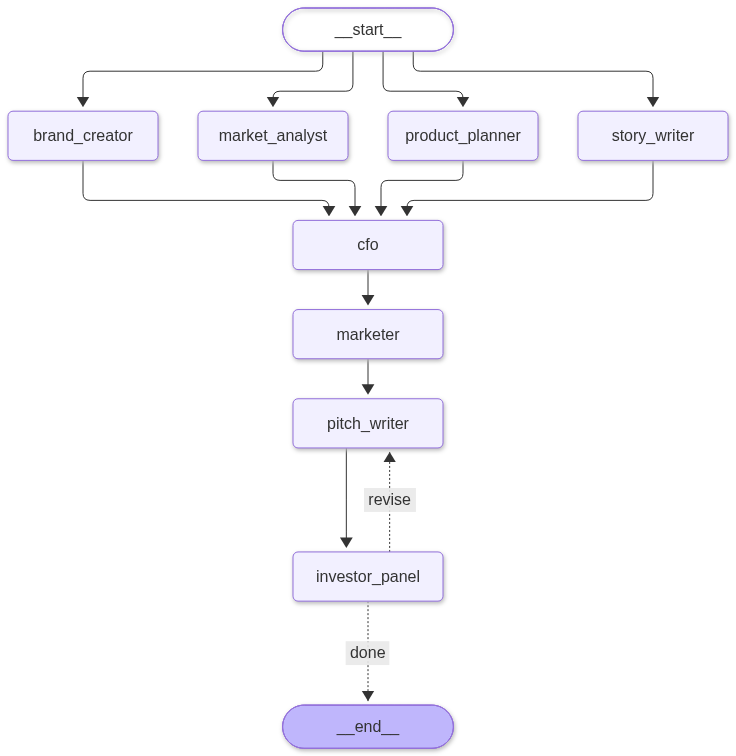

In [ ]:
from IPython.display import Image
try:
    display(Image(studio.get_graph().draw_mermaid_png()))
except Exception:
    print(studio.get_graph().draw_mermaid())

In [72]:
# Bonus 5: Observability - count LLM calls, tokens and time per agent
import time
from collections import defaultdict
from langchain_core.callbacks import BaseCallbackHandler


class StudioTracker(BaseCallbackHandler):
    """Gets a message every time an agent calls the LLM, and counts it per agent."""

    def __init__(self):
        self.calls = defaultdict(int)
        self.tokens = defaultdict(int)
        self.seconds = defaultdict(float)
        self.started = {}

    def _agent_name(self, metadata):
        # e.g. "market_analyst:abc|model:xyz" -> "market_analyst"
        path = (metadata or {}).get("langgraph_checkpoint_ns", "")
        return path.split(":")[0] or "other"

    def on_chat_model_start(self, serialized, messages, *, run_id, metadata=None, **kwargs):
        agent = self._agent_name(metadata)
        self.started[run_id] = (agent, time.time())
        self.calls[agent] += 1

    def on_llm_end(self, response, *, run_id, **kwargs):
        agent, start = self.started.pop(run_id, ("other", time.time()))
        self.seconds[agent] += time.time() - start
        for generation_list in response.generations:
            for gen in generation_list:
                usage = getattr(getattr(gen, "message", None), "usage_metadata", None)
                if usage:
                    self.tokens[agent] += usage.get("total_tokens", 0)

    def report(self):
        print(f"{'Agent':<18}{'Calls':>6}{'Tokens':>9}{'LLM time (s)':>14}")
        print("-" * 47)
        for agent in self.calls:
            print(f"{agent:<18}{self.calls[agent]:>6}{self.tokens[agent]:>9}{self.seconds[agent]:>14.1f}")
        print("-" * 47)
        print(f"{'TOTAL':<18}{sum(self.calls.values()):>6}{sum(self.tokens.values()):>9}")

    def as_dict(self):
        return {
            agent: {"llm_calls": self.calls[agent], "tokens": self.tokens[agent],
                    "llm_seconds": round(self.seconds[agent], 1)}
            for agent in self.calls
        }


print("Tracker ready")

Tracker ready


## 6. 🚀 Launch!

Run your venture studio on `MY_IDEA` and collect the results into the `launch_kit` dictionary. You can fill it straight from your agents' outputs, or have a final "assembler" agent build it.

In [74]:
# Run your venture studio on MY_IDEA and build the launch kit
# (for LlamaIndex, ADK or CrewAI you can use `await` directly in this cell)
import time

idea_text = f"Idea: {MY_IDEA['idea']}\nSector: {MY_IDEA['sector']}"

tracker = StudioTracker()

start_time = time.time()
final_state = studio.invoke({"idea": idea_text}, config={"callbacks": [tracker]})
run_seconds = round(time.time() - start_time, 1)
print(f"\n Full run took {run_seconds} seconds\n")
tracker.report()

# Take each agent's output from the shared state
market = final_state["market"]
brand = final_state["brand"]
product = final_state["product"]
story = final_state["story"]
finance = final_state["finance"]
marketing = final_state["marketing"]
pitch = final_state["pitch"]
rounds = final_state["feedback_rounds"]

launch_kit = {
    "startup_name": brand.startup_name,
    "one_liner": brand.one_liner,
    "target_customers": product.target_customers,
    "market_insights": market.market_insights,
    "competitors": [c.model_dump() for c in market.competitors],
    "mvp_features": product.mvp_features,
    "pricing": finance.pricing,
    "unit_economics": {
        "price_per_month_usd": finance.price_per_month_usd,
        "cost_to_serve_per_month_usd": finance.cost_to_serve_per_month_usd,
        "cac_usd": finance.cac_usd,
        "monthly_churn_pct": finance.monthly_churn_pct,
        "ltv_usd": finance.ltv_usd,
        "ltv_to_cac": finance.ltv_to_cac,
        "cac_payback_months": finance.cac_payback_months,
        "verdict": finance.verdict,
    },
    "marketing_campaign": marketing.model_dump(),
    "investor_pitch": pitch.slides,
    "investor_feedback": [
        {
            "round": r["round"],
            "average_score": r["avg_score"],
            "scores": [s.model_dump() for s in r["scores"]],
        }
        for r in rounds
    ],
    "sample_story": story.model_dump(),
    "names_tried": brand.names_tried,
    "run_stats": {"total_seconds": run_seconds, "total_llm_calls": sum(tracker.calls.values()),
                  "total_tokens": sum(tracker.tokens.values()), "per_agent": tracker.as_dict()},
}

print(f"Launch kit built for {launch_kit['startup_name']} after {len(rounds)} investor round(s)")

Brand Creator working...
Market Analyst working...
Product Planner working...
🌙 Story Writer working...
check_story_safety {'story': 'Milo found a tiny silver key in the garden behind the blue flowerpot. It opened a little door in the trunk of an old oak tree. Inside, there was a cozy room with soft blankets, warm tea, and a round lantern glowing like a moon. A friendly squirrel with a red scarf invited Milo to sit down. Together they listened to the gentle whisper of the leaves and watched little fireflies dance in the air. The squirrel shared a basket of shiny acorns that looked like marbles, and Milo placed the silver key on a shelf beside a teacup. Everything in the room felt peaceful and kind, and the oak tree seemed to hum a sleepy song. When it was time to go, Milo waved goodnight to the squirrel and the tree, then followed a path of soft grass back home, feeling calm and happy.'}
   🛡️ Final safety check on the bedtime story: safe=True, words=145
check_name_availability {'name'

In [ ]:
import json

with open("launch_kit.json", "w", encoding="utf-8") as f:
    json.dump(launch_kit, f, indent=2, ensure_ascii=False)
print("Saved version")

Saved version 5 (own tool added, before story-check fix)


## 7. ✅ Mission Check

The checker verifies that every required section is present. Then `show_launch_kit()` renders your Launch Kit as a report, ready for Demo Day.

In [50]:
ready = check_launch_kit(launch_kit)

✅ startup_name        
✅ one_liner           
✅ target_customers    
✅ market_insights     
✅ competitors         
✅ mvp_features        
✅ pricing             
✅ unit_economics      
✅ marketing_campaign  
✅ investor_pitch      
✅ investor_feedback   

✨ Extra sections (nice!): sample_story, names_tried

Launch readiness: 11/11
🚀 All systems go! Your startup is ready for Demo Day.


In [75]:
show_launch_kit(launch_kit)

# 🚀 Lullava

> Lullava turns parents’ dreams into magical, personalized bedtime stories that help kids drift off to sleep with a little wonder.

## Target Customers

- Parents of children ages 3-8 who want a calm, personalized bedtime routine and enjoy creative storytelling
- Time-strapped working parents who journal dreams or like reflecting on them, and want a playful way to reuse that content with their kids
- Gift-giving caregivers or relatives looking for a unique, emotionally meaningful bedtime app experience for families

## Market Insights

The entertainment market is sized at USD 210 bn and is growing at 9.2% annually, which is strong for a consumer subscription product. Users in this market spend about USD 12 per month on average, so a family-friendly product should price carefully against that baseline. Key trends favor this idea: generative-AI personalised content, niche communities over mass platforms, and offline-first experiences. Main risks are content moderation, subscription fatigue, and fast-moving copycats. Benchmark CAC is USD 18 and benchmark monthly churn is 9%, so retention and sharing loops will matter a lot.

## Competitors

-
  - **name**: SnoozeStory
  - **price**: $7.99/month
  - **weakness**: Generic stories, nothing from the family's own life
  - **how_we_beat_them**: Turn the parent’s real dream into a uniquely personal bedtime story, which makes the content emotionally sticky and far harder to copy than generic AI stories.
-
  - **name**: DreamLog
  - **price**: Free / $3.99 pro
  - **weakness**: Analysis only, no creative output
  - **how_we_beat_them**: Position as the only product that transforms dream journaling into a child-safe creative experience, not just dream tracking or interpretation.

## Mvp Features

- Dream input flow: simple text prompt with guided prompts to capture a parent’s dream in 1-2 minutes
- AI story generator: transform the dream into a short, age-appropriate bedtime story personalized with the child’s name and preferences
- Child-safe story style controls: let parents choose tone, length, and age band (e.g. 3-5, 6-8) to keep stories appropriate
- Story playback/read mode: clean reading screen optimized for bedtime, with large text and optional text-to-speech
- Save and reuse stories: basic library of generated stories with favorites and recent history
- Sharing/export: easy copy or share via link/PDF for use outside the app

## Pricing

Premium subscription at $6.99/month, positioned between DreamLog's $3.99 pro and SnoozeStory's $7.99/month, with the personalized dream-to-story transformation as the core value driver.

## Unit Economics

- **price_per_month_usd**: 6.99
- **cost_to_serve_per_month_usd**: 1.25
- **cac_usd**: 18.0
- **monthly_churn_pct**: 9.0
- **ltv_usd**: 63.78
- **ltv_to_cac**: 3.54
- **cac_payback_months**: 3.1
- **verdict**: Healthy: investors like LTV/CAC >= 3.

## Marketing Campaign

- **slogan**: Turn dreams into a bedtime story your child can drift off to.
- **launch_channels**:
  - Instagram Reels and Stories
  - Facebook parenting groups
  - Partner newsletters with parenting bloggers and family creators
  - App Store launch with featured screenshots and reviews
- **social_posts**:
  - Bedtime, but make it magical. ✨ Lullava turns your dream notes into personalized stories your child will actually ask for again.
  - Too tired to invent one more bedtime story? Lullava transforms your dreams into a calm, cozy tale in minutes—made for sleepy parents and little imaginations.
  - From journaled dream to lights-out storytime: Lullava helps turn bedtime into a sweet ritual your kid will love. $6.99/month for a little wonder every night.

## Investor Pitch

- Problem: Bedtime for parents of 3-8 year olds is a nightly negotiation: kids want something soothing and special, parents want something fast, safe, and repeatable. The current options are generic story apps, one-off books, or another subscription that doesn’t feel tied to the family’s real life. In the broader $210B entertainment market, we’re not building ‘more content’—we’re building a specific bedtime ritual category where novelty, personalization, and calm matter more than volume.
- Solution: Lullava is the dream-to-story bedtime ritual: a parent types a dream in 1-2 minutes, and we turn it into a child-safe story starring their child, tuned by age, tone, and length. Example: Milo finds a silver key, opens a door in an oak tree, meets a friendly squirrel, and drifts off feeling calm and safe. That emotional loop is the product: the parent already has the dream, we transform it into a one-of-one story, and the family gets a memorable nightly ritual that feels owned—not generic AI.
- Market: We are focused on a narrower, defendable subcategory: bedtime entertainment for parents of children ages 3-8 who want a calm routine and already use story or audio content. This segment sits inside a $210B entertainment market growing 9.2% annually, but our real wedge is repeat bedtime use, not broad entertainment. We price at $6.99/month, below the ~$12/month category spend benchmark and between DreamLog’s $3.99 pro tier and SnoozeStory’s $7.99/month, so we can test willingness to pay without pricing like a premium toy app.
- Product: First 90 days ship only what proves the ritual: 1) a 1-minute guided dream input flow, 2) child-safe story generation with age-band, tone, and length controls, 3) bedtime reading/playback with optional text-to-speech, and 4) saved favorites so the best stories become part of a family library. To validate demand before launch, we’ll run pricing and landing-page tests around the ‘dream-to-story bedtime ritual,’ measure conversion from parent communities and creator traffic, and track whether families come back for a second, third, and seventh story—because repeat use is the habit proof we need.
- Business model: Premium subscription at $6.99/month. CFO assumptions: cost to serve $1.25/month, CAC $18, monthly churn 9%. That implies gross margin of 82%, LTV of $63.78, LTV/CAC of 3.54, and CAC payback in 3.1 months. We agree those assumptions must be earned, so the first tests are designed to validate them: pricing sensitivity to confirm $6.99, channel experiments to measure real CAC by source, and retention cohorts to see whether the dream mechanic creates weekly or nightly repeat use instead of one-time novelty.
- Ask: We’re raising to prove three things fast: parents will pay, parents will return, and parents will share. In the first 90 days we will launch the MVP, run pricing tests, measure acquisition by channel, and validate repeat usage with saved-story and bedtime-return cohorts. We’re looking for investors who want an ownable family ritual brand—not just another AI content tool—and who believe a small, emotionally magnetic habit can become a durable subscription business.

## Investor Feedback

-
  - **round**: 1
  - **average_score**: 6.3
  - **scores**:
    -
      - **investor**: Ada Okafor
      - **score**: 6
      - **verdict**: maybe
      - **feedback**: Show me the numbers. The unit economics are directionally attractive on paper, and the product wedge is clear enough to be testable: a tight bedtime use case, child-safe outputs, and a simple MVP that can launch fast. But the market framing is too broad, the moat is still mostly narrative, and the $18 CAC benchmark feels hand-wavy without a concrete acquisition plan or evidence those assumptions are achievable. To get to an 8+, I’d need a sharper ICP, a believable channel strategy, and proof that parents will pay and repeatedly use this for more than novelty.
    -
      - **investor**: Rex Moon
      - **score**: 7
      - **verdict**: maybe
      - **feedback**: Will this change how people live? Potentially yes, because you’ve found a genuinely intimate ritual and turned it into a product with emotional leverage. I like the category creation angle and the bedtime-first wedge, but right now it still feels a little too close to ‘personalized AI stories’ unless you prove the dream-to-story magic is consistently delightful and not just novel for a week. The numbers are directionally healthy, but I’d want stronger evidence that parents will repeatedly pay for this and that the dream input step becomes a habit, not friction. 
    -
      - **investor**: Priya Shah
      - **score**: 6
      - **verdict**: maybe
      - **feedback**: What ships in the first 90 days is actually pretty clear: a tight MVP centered on dream input, story generation, and bedtime reading, with a focused wedge on parents of kids 3-8. I like the specific pricing and the attempt at unit economics, but the market framing is too broad and the customer definition is still fuzzy across parents, journaling users, and gift-givers. The numbers need more realism before I’d get to an 8: CAC is a benchmark, not evidence; 9% monthly churn is high for a subscription product; and the moat sounds more emotional than defensible. Prove the first cohort will pay, use it nightly, and share it without adding feature bloat.
-
  - **round**: 2
  - **average_score**: 6.7
  - **scores**:
    -
      - **investor**: Ada Okafor
      - **score**: 6
      - **verdict**: maybe
      - **feedback**: This has a clear wedge and a real consumer pain, and I like the narrow product scope and the attempt to frame unit economics instead of vibes. But the numbers are still too convenient: $18 CAC, 9% monthly churn, and 82% gross margin look hand-wavy without evidence from even proxy tests, and the market framing is broad entertainment rather than a defendable bedtime subcategory. Show me the numbers: prove willingness to pay with pricing tests, validate acquisition costs with actual channel experiments, and explain why this becomes a habit strong enough to beat novelty and churn.
    -
      - **investor**: Rex Moon
      - **score**: 7
      - **verdict**: maybe
      - **feedback**: This has a real wedge and a sharp ritual, not a me-too AI toy: parents of 3-8 year olds want calm, fast, personalized bedtime help, and the sample workflow is easy to picture. The unit economics are credible on paper, but the story still feels more like a feature than a category unless you prove a repeatable nightly habit and an emotionally magnetic brand that parents will remember. Need stronger evidence that this becomes a must-have ritual, not a cute novelty, and a more distinct name/story world that feels ownable beyond generic AI bedtime stories.
    -
      - **investor**: Priya Shah
      - **score**: 7
      - **verdict**: maybe
      - **feedback**: This is a tight MVP with a believable wedge: a specific bedtime ritual for parents of 3-8 year olds, clear 90-day shipping priorities, and unit economics that at least hang together on paper. I like that you’ve avoided feature bloat and named concrete channels, but the ICP is still a bit broad and the CAC/churn assumptions feel optimistic without evidence of a repeatable acquisition loop or why this becomes a nightly habit versus a clever one-off. What ships in the first 90 days? Make that proof tighter: show demand before launch, prove parents will pay, and validate that the dream-to-story mechanic creates real repeat usage—not just novelty.
-
  - **round**: 3
  - **average_score**: 7.7
  - **scores**:
    -
      - **investor**: Ada Okafor
      - **score**: 7
      - **verdict**: maybe
      - **feedback**: The wedge is clear and emotionally compelling: bedtime ritual is a real use case, the product is specific, and the MVP/test plan is sensible for pre-launch. Show me the numbers is partly answered with a coherent model, and the unit economics look investable on paper if churn and CAC are real. What’s missing is proof that this is a big enough category to build venture-scale on and that the moat is more than prompt-driven personalization—defensibility, repeat behavior, and organic sharing need to be demonstrated after launch. The $210B market framing feels too broad; I want a tighter, bottom-up TAM and evidence the $6.99 price can support efficient acquisition outside warm traffic.
    -
      - **investor**: Rex Moon
      - **score**: 8
      - **verdict**: Invest
      - **feedback**: Will this change how people live? Yes — if the ritual works, this is not just another story app, it’s a new bedtime behavior built around a deeply emotional parent-child moment. The positioning is strong, the category is specific, and the MVP is sensibly focused on proving the core ritual fast; the dream-to-story hook is memorable and ownable. What must change is proving the economics and repeat demand with ruthless honesty after launch: your CAC, churn, and payback look plausible on paper, but the whole business lives or dies on whether families actually make this a habit, not a novelty.
    -
      - **investor**: Priya Shah
      - **score**: 8
      - **verdict**: maybe
      - **feedback**: This is a focused MVP with a clear ritual, sensible pricing, and a credible first-90-days plan. I like that you’re not pretending to have retention yet and that you’ve named the exact proof points: conversion, channel CAC, and repeat use from the bedtime habit. The risk is still category vagueness and novelty decay—$210B entertainment is too broad, and I want sharper evidence that this is a distinct bedtime workflow families will actually adopt and keep using. What ships in the first 90 days?

## Sample Story

- **parent_dream**: I dreamed I found a tiny silver key in the garden behind the blue flowerpot. It opened a little door in the trunk of an old oak tree, and inside was a cozy room with soft blankets, warm tea, and a lantern glowing like the moon. A friendly squirrel in a red scarf invited me to sit down while fireflies danced outside.
- **bedtime_story**: Milo found a tiny silver key in the garden behind the blue flowerpot. It opened a little door in the trunk of an old oak tree. Inside, there was a cozy room with soft blankets, warm tea, and a round lantern glowing like a moon. A friendly squirrel with a red scarf invited Milo to sit down. Together they listened to the gentle whisper of the leaves and watched little fireflies dance in the air. The squirrel shared a basket of shiny acorns that looked like marbles, and Milo placed the silver key on a shelf beside a teacup. Everything in the room felt peaceful and kind, and the oak tree seemed to hum a sleepy song. When it was time to go, Milo waved goodnight to the squirrel and the tree, then followed a path of soft grass back home, feeling calm and happy.

## Names Tried

- DreamSprout — Pick another name.
- Lullava — Looks usable!

## Run Stats

- **total_seconds**: 31.8
- **total_llm_calls**: 27
- **total_tokens**: 31788
- **per_agent**:
  - **brand_creator**:
    - **llm_calls**: 3
    - **tokens**: 1974
    - **llm_seconds**: 3.9
  - **market_analyst**:
    - **llm_calls**: 3
    - **tokens**: 2523
    - **llm_seconds**: 4.1
  - **product_planner**:
    - **llm_calls**: 1
    - **tokens**: 385
    - **llm_seconds**: 2.7
  - **story_writer**:
    - **llm_calls**: 2
    - **tokens**: 1432
    - **llm_seconds**: 3.3
  - **cfo**:
    - **llm_calls**: 3
    - **tokens**: 3047
    - **llm_seconds**: 3.6
  - **marketer**:
    - **llm_calls**: 1
    - **tokens**: 430
    - **llm_seconds**: 1.8
  - **pitch_writer**:
    - **llm_calls**: 5
    - **tokens**: 12325
    - **llm_seconds**: 15.2
  - **investor_panel**:
    - **llm_calls**: 9
    - **tokens**: 9672
    - **llm_seconds**: 17.5

## 8. 🪞 Reflection *(double-click to edit)*

1. **Which pattern added the most value, and why?** _…_
2. **Where did your agents struggle** (hallucinations, ignored tools, loops, formatting)? **How did you fix it?** _…_
3. **How many LLM calls does one run take, and how long does it take?** Where could you cut cost or latency? _…_
4. **If you rebuilt this in another framework, what would be easier or harder?** _…_
5. **What would need to change before real founders could use this?** _…_

## 🌟 Bonus Zone

Tackling a bonus mission? Build it here, and say in the design doc which one you did.

In [ ]:
# Bonus missions go here
# Built Observability - count LLM calls, tokens and time per agent that we did yesterday and you said that is most important part
# already integrated on my system

## 📬 Before You Submit

- [ ] *Restart Kernel → Run All* runs without errors
- [ ] The design doc and the reflection are filled in
- [ ] The Mission Check shows **11/11** ✅
- [ ] There are no API keys in the notebook (they live in `.env`)

Good luck, founder! May your startup be the next unicorn. 🦄🚀